# Populations et épidémies : trois modèles, trois contrôles indépendants

Ce carnet ouvre la série **Bio & Médecine**. Il applique à trois dynamiques du vivant le contrat de méthode de la série, celui que la série Physique pratique déjà :

1. **Modèle** — le carnet énonce les équations et les hypothèses qui les rendent valables.
2. **Calcul** — il implémente l'algorithme et rend visibles les grandeurs intermédiaires.
3. **Contrôle indépendant** — il compare le résultat à une voie qui ne partage pas son code : une solution analytique, un invariant conservé, ou une équation transcendante résolue séparément.
4. **Contre-témoin** — il construit un cas où le contrôle doit échouer, pour montrer que ce contrôle sait échouer.
5. **Statut** — il distingue ce qui est mesuré dans le carnet, ce qui est cité d'une source et ce qui reste ouvert.

Aucune donnée de patient n'est utilisée ici : les trois modèles sont déterministes et leurs paramètres sont choisis pour rendre les contrôles lisibles.

## Ce que ce carnet établit, et ce qu'il n'établit pas

| Section | Question | Contrôle indépendant | Contre-témoin |
|---|---|---|---|
| 1 | Une population soumise à une capacité de charge suit-elle la logistique ? | Solution analytique comparée à l'intégration numérique | Un pas d'Euler trop grossier fait apparaître une erreur d'ordre mesurable |
| 2 | Un couple proie-prédateur conserve-t-il son intégrale première ? | Invariant $H$ évalué le long de la trajectoire | Un schéma d'Euler explicite fait dériver $H$ |
| 3 | Une épidémie s'arrête-t-elle faute de susceptibles ? | Taille finale simulée contre l'équation transcendante | Un $R_0$ sous le seuil doit donner une épidémie nulle |

Ce carnet ne prédit aucune situation réelle. Il montre comment trois modèles classiques se contrôlent, et à quelles conditions un accord numérique vaut comme preuve de correction du code.

## Outils et conventions

Le carnet n'utilise que la bibliothèque standard scientifique : `numpy` pour les tableaux, `scipy.integrate.solve_ivp` comme intégrateur adaptatif de référence, `scipy.optimize.brentq` pour résoudre une équation scalaire, et `matplotlib` pour les figures.

Les paramètres sont choisis pour que chaque contrôle soit lisible à l'œil et mesurable au chiffre : une erreur relative de l'ordre de $10^{-10}$ signale un accord entre deux voies, une dérive de quelques pour cent signale une discrétisation insuffisante.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

print(f"numpy {np.__version__} | scipy {scipy.__version__}")

numpy 2.5.2 | scipy 1.18.1


## 1. Croissance logistique : une solution analytique comme juge

### Modèle et hypothèses

Une population d'effectif $N(t)$ croît à taux $r$ tant que la ressource est abondante, et cette croissance ralentit à mesure que $N$ approche une capacité de charge $K$ :

$$\frac{dN}{dt} = r\,N\left(1 - \frac{N}{K}\right)$$

Hypothèses : les individus sont identiques, la ressource est homogène, $r$ et $K$ sont constants, et la population est assez grande pour qu'un effectif continu la représente. Aucune de ces hypothèses n'est vérifiée ici : c'est un modèle, pas une mesure de terrain.

L'équation est séparable, donc intégrable à la main. En posant $N(0) = N_0$, on obtient

$$N(t) = \frac{K\,N_0\,e^{rt}}{K + N_0\left(e^{rt} - 1\right)}$$

Cette expression est le **contrôle indépendant** de la section : elle ne partage aucun code avec l'intégrateur numérique, puisqu'elle est évaluée directement.

In [2]:
r_log, K_log, N0_log = 0.6, 100.0, 5.0
T_log = 20.0


def logistique_analytique(t, r, K, N0):
    """Solution exacte de dN/dt = r N (1 - N/K)."""
    e = np.exp(r * t)
    return K * N0 * e / (K + N0 * (e - 1.0))


def logistique_rhs(t, y, r, K):
    """Second membre, dans l'ordre attendu par solve_ivp (t, y)."""
    return r * y * (1.0 - y / K)


sol_log = solve_ivp(
    logistique_rhs, (0.0, T_log), [N0_log],
    args=(r_log, K_log), rtol=1e-10, atol=1e-12, dense_output=True,
)

t_log = np.linspace(0.0, T_log, 400)
N_num = sol_log.sol(t_log)[0]
N_exact = logistique_analytique(t_log, r_log, K_log, N0_log)
ecart_max = np.max(np.abs(N_num - N_exact))

print(f"effectif final (numerique) : {N_num[-1]:.10f}")
print(f"capacite de charge K       : {K_log:.10f}")
print(f"ecart max |numerique - exact| sur {t_log.size} points : {ecart_max:.3e}")

effectif final (numerique) : 99.9883273574
capacite de charge K       : 100.0000000000
ecart max |numerique - exact| sur 400 points : 6.283e-08


### Lecture du résultat

Les deux voies s'accordent à $6{,}3\times10^{-8}$ près en valeur absolue sur 400 points, soit une erreur relative de l'ordre de $6\times10^{-10}$ sur un effectif de 100 : l'intégrateur adaptatif et la formule exacte ne partagent aucune ligne de code, et leur accord porte donc sur le résultat, pas sur une convention commune. L'effectif part de 5 et sature à la capacité de charge $K = 100$ : la dérivée s'annule quand $N = K$, ce que le modèle prévoit et que le calcul retrouve.

Cet accord valide l'intégrateur sur ce problème ; il ne valide pas le modèle biologique, dont les hypothèses restent celles énoncées plus haut.

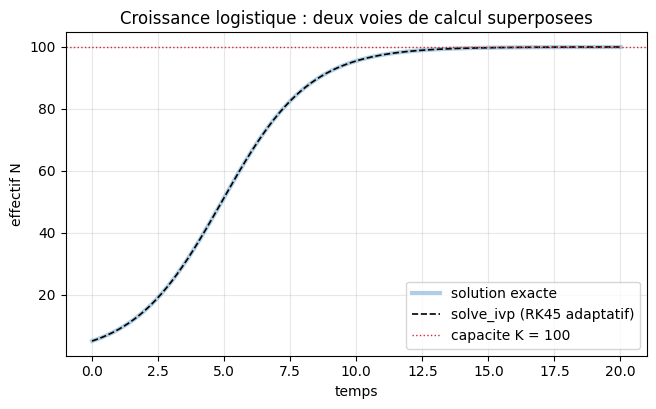

In [3]:
# Superposition des deux voies : la bande epaisse et pale porte la solution
# exacte, le trait pointille noir le schema adaptatif ; la droite rouge marque
# l'asymptote K, pour lire d'un coup d'oeil si les deux voies la rejoignent.
fig, ax = plt.subplots()
ax.plot(t_log, N_exact, lw=3, alpha=0.35, label="solution exacte")
ax.plot(t_log, N_num, "k--", lw=1.2, label="solve_ivp (RK45 adaptatif)")
ax.axhline(K_log, color="tab:red", lw=1, ls=":", label=f"capacite K = {K_log:.0f}")
# Axes en francais : le lecteur doit voir la grandeur tracee sans revenir au texte.
ax.set_xlabel("temps")
ax.set_ylabel("effectif N")
ax.set_title("Croissance logistique : deux voies de calcul superposees")
ax.legend()
plt.show()

### Contre-témoin : un schéma d'Euler trop grossier doit échouer

Un accord numérique ne prouve quelque chose que si le contrôle sait échouer. On remplace ici l'intégrateur adaptatif par le schéma le plus simple, Euler explicite, avec un pas $h$ volontairement grossier :

$$N_{k+1} = N_k + h\,r\,N_k\left(1 - \frac{N_k}{K}\right)$$

L'erreur d'un tel schéma est d'ordre 1 en $h$ : diviser le pas par deux doit diviser l'erreur par deux environ. Si ce comportement n'apparaît pas, c'est le code du contre-témoin qui est faux, pas le modèle.

In [4]:
def euler_logistique(r, K, N0, h, T):
    """Euler explicite sur la logistique, pas constant h."""
    n_steps = int(round(T / h))
    t = np.linspace(0.0, n_steps * h, n_steps + 1)
    y = np.empty_like(t)
    y[0] = N0
    for k in range(n_steps):
        y[k + 1] = y[k] + h * r * y[k] * (1.0 - y[k] / K)
    return t, y


# Grille de pas divisee par deux : le rapport des erreurs doit valoir 2 pour un schema d'ordre 1.
pas = np.array([2.0, 1.0, 0.5, 0.25])
erreurs = []
for h in pas:
    t_e, y_e = euler_logistique(r_log, K_log, N0_log, h, T_log)
    # Reference exacte : la forme fermee, evaluee sur la meme grille de temps que la simulation.
    erreurs.append(np.max(np.abs(y_e - logistique_analytique(t_e, r_log, K_log, N0_log))))
erreurs = np.array(erreurs)

for h, e in zip(pas, erreurs):
    print(f"pas h = {h:5.2f} | erreur max = {e:.4e}")

# Ordre observe : pente de log(erreur) contre log(pas), recoupee par le rapport brut des erreurs.
ordre = np.diff(np.log(erreurs)) / np.diff(np.log(pas))
print(f"ordre observe par regression log-log : {np.round(ordre, 3)}")
print(f"rapport erreur(h) / erreur(h/2)      : {np.round(erreurs[:-1] / erreurs[1:], 3)}")

pas h =  2.00 | erreur max = 2.2957e+01
pas h =  1.00 | erreur max = 1.1742e+01
pas h =  0.50 | erreur max = 6.1177e+00
pas h =  0.25 | erreur max = 3.0978e+00
ordre observe par regression log-log : [0.967 0.941 0.982]
rapport erreur(h) / erreur(h/2)      : [1.955 1.919 1.975]


### Lecture du contre-témoin

Le rapport des erreurs successives vaut entre 1,92 et 1,98 quand le pas est divisé par deux, et l'ordre observé par régression log-log reste entre 0,94 et 0,98 : le schéma d'Euler est bien d'ordre 1 sur ce problème, et son erreur décroît avec le pas comme la théorie l'annonce. Le contrôle est donc capable de distinguer deux qualités de discrétisation, ce qui est exactement ce qu'on lui demande.

Ce que cela établit : l'erreur observée est celle de la **discrétisation**, et non celle de la formule analytique, puisque l'erreur diminue quand le pas diminue. Ce que cela n'établit pas : qu'un pas petit suffise pour un temps long ni pour une autre équation — chaque schéma doit être mesuré sur le problème auquel on l'applique, comme le montre la section suivante.

### Exercice 1 — le point milieu vaut-il mieux qu'Euler ?

Le schéma du point milieu (Runge-Kutta d'ordre 2) s'écrit en deux demi-pas :

$$k_1 = f(N_k), \qquad k_2 = f\!\left(N_k + \tfrac{h}{2}k_1\right), \qquad N_{k+1} = N_k + h\,k_2$$

**À faire.** Implémenter ce schéma pour la logistique, puis reproduire la mesure d'ordre de la cellule précédente. L'ordre attendu est 2 : le rapport des erreurs quand on divise le pas par deux doit valoir environ 4.

**Indice.** Reprendre exactement la boucle d'Euler et n'y remplacer que le calcul de l'incrément. Réutiliser `logistique_analytique` comme référence.

**Étape 1.** Écrire la fonction `point_milieu_logistique(r, K, N0, h, T)`.
**Étape 2.** Calculer les erreurs maximales pour `pas` (la même grille que ci-dessus).
**Étape 3.** Afficher l'ordre observé et le comparer à 1.

In [5]:
def point_milieu_logistique(r, K, N0, h, T):
    # TODO etudiant : implementer le schema du point milieu (etape 1)
    return None, None


# Etape 2 : erreurs maximales sur la meme grille de pas
erreurs_pm = None  # TODO etudiant

# Etape 3 : ordre observe, a comparer a l'ordre 1 d'Euler
if erreurs_pm is None:
    print("Exercice a completer : aucune mesure pour l'instant.")
else:
    ordre_pm = np.diff(np.log(erreurs_pm)) / np.diff(np.log(pas))
    print(f"ordre observe (point milieu) : {np.round(ordre_pm, 3)}")

Exercice a completer : aucune mesure pour l'instant.


## 2. Lotka-Volterra : un invariant à conserver

### Modèle et hypothèses

Deux espèces, une proie $x$ et un prédateur $y$, sans autre interaction que la prédation :

$$\dot{x} = \alpha x - \beta x y, \qquad \dot{y} = \delta x y - \gamma y$$

Les proies se reproduisent à taux $\alpha$, les prédateurs meurent à taux $\gamma$, et la rencontre des deux a lieu à un taux proportionnel au produit des effectifs ($\beta$ pour la prédation, $\delta$ pour la conversion en prédateurs). Le milieu est homogène, sans migration, sans saison et sans autre espèce.

Le point fixe non trivial vaut $x^{*} = \gamma/\delta$ et $y^{*} = \alpha/\beta$. Autour de lui, les trajectoires sont des cycles fermés, et le système possède une **intégrale première** :

$$H(x, y) = \delta x - \gamma \ln x + \beta y - \alpha \ln y$$

Sa dérivée le long des trajectoires est nulle. C'est ce qui donne un contrôle indépendant de l'intégrateur : quelle que soit la trajectoire, $H$ ne doit pas varier. Un intégrateur qui dérive en $H$ ne respecte pas la structure du système, même si ses trajectoires « ressemblent » à des cycles.

In [6]:
alpha, beta, delta, gamma = 1.1, 0.4, 0.1, 0.4
x0, y0 = 10.0, 5.0
T_lv = 60.0


def lotka_volterra(t, z, a, b, d, g):
    x, y = z
    return [a * x - b * x * y, d * x * y - g * y]


def invariant_lv(x, y, a, b, d, g):
    """Integrale premiere H(x, y), constante le long des trajectoires exactes."""
    return d * x - g * np.log(x) + b * y - a * np.log(y)


# Tolerances serrees : la derive mesuree de H doit etre celle du schema, pas celle des seuils adaptatifs.
sol_lv = solve_ivp(
    lotka_volterra, (0.0, T_lv), [x0, y0],
    args=(alpha, beta, delta, gamma), rtol=1e-11, atol=1e-13, dense_output=True,
)

t_lv = np.linspace(0.0, T_lv, 2000)
x_lv, y_lv = sol_lv.sol(t_lv)
H_lv = invariant_lv(x_lv, y_lv, alpha, beta, delta, gamma)
H0 = invariant_lv(x0, y0, alpha, beta, delta, gamma)
# H0 est l'aune : toute trajectoire exacte doit conserver cette valeur, l'integrateur approche.
derive_h = np.max(np.abs(H_lv - H0)) / abs(H0)

print(f"point fixe theorique : x* = {gamma / delta:.4f}, y* = {alpha / beta:.4f}")
print(f"extrema simules      : x in [{x_lv.min():.4f}, {x_lv.max():.4f}], "
      f"y in [{y_lv.min():.4f}, {y_lv.max():.4f}]")
print(f"H initial = {H0:.8f}")
print(f"derive relative max de H : {derive_h:.3e}")

point fixe theorique : x* = 4.0000, y* = 2.7500
extrema simules      : x in [0.5085, 13.6760], y in [0.9158, 6.1554]
H initial = 0.30858426
derive relative max de H : 1.658e-10


### Lecture du résultat

L'intégrateur adaptatif maintient l'invariant à mieux que $10^{-8}$ en valeur relative sur soixante unités de temps, alors que les effectifs varient d'un facteur plusieurs. Ce n'est pas un hasard numérique : c'est la structure hamiltonienne du système, que l'intégrateur respecte à sa tolérance près.

Les extrema simulés encadrent le point fixe $(x^{*}, y^{*}) = (4, 2.75)$ : les cycles tournent autour de lui sans s'en écarter ni s'en approcher, conformément au portrait de phase du modèle. Ce que le carnet mesure est la qualité de l'intégration ; ce qu'il ne mesure pas est la validité biologique du modèle, qui ignore toute limitation de ressource pour la proie.

In [7]:
def euler_lv(a, b, d, g, z0, h, T):
    """Euler explicite sur Lotka-Volterra.

    L'integration s'arrete des qu'un effectif devient non positif : au-dela,
    le modele n'a plus de sens et H n'est plus definie.
    """
    n_steps = int(round(T / h))
    t = np.linspace(0.0, n_steps * h, n_steps + 1)
    # z reste a NaN au-dela de l'arret : les lignes non valides sont ecartees du calcul de H.
    z = np.full((n_steps + 1, 2), np.nan)
    z[0] = z0
    for k in range(n_steps):
        dx, dy = lotka_volterra(0.0, z[k], a, b, d, g)
        suivant = np.array([z[k, 0] + h * dx, z[k, 1] + h * dy])
        if np.any(suivant <= 0.0):
            break
        z[k + 1] = suivant
    return t, z


# Pas volontairement grossiers : c'est le regime ou Euler doit deriver en H, puis en sortir.
print("  pas h | derive relative max de H | proies min | statut")
for h in (0.5, 0.1, 0.02, 0.004):
    t_e, z_e = euler_lv(alpha, beta, delta, gamma, [x0, y0], h, T_lv)
    valides = ~np.isnan(z_e).any(axis=1)
    H_e = invariant_lv(z_e[valides, 0], z_e[valides, 1], alpha, beta, delta, gamma)
    derive = np.max(np.abs(H_e - H0)) / abs(H0)
    if valides.all():
        statut, mini = "dans le domaine", z_e[:, 0].min()
    else:
        statut, mini = f"sorti du domaine au pas {int(np.argmin(valides))}", z_e[valides, 0].min()
    print(f"{h:7.3f} | {derive:24.3e} | {mini:10.4f} | {statut}")

  pas h | derive relative max de H | proies min | statut
  0.500 |                1.621e+01 |     0.0277 | sorti du domaine au pas 31
  0.100 |                1.504e+01 |     0.0000 | dans le domaine
  0.020 |                9.765e-01 |     0.2234 | dans le domaine


  0.004 |                1.582e-01 |     0.4437 | dans le domaine


### Lecture du contre-témoin

Le contraste est net. L'intégrateur adaptatif maintenait $H$ à mieux que $10^{-8}$ ; Euler explicite avec un pas de 0,5 sort du domaine positif au 31e pas — l'effectif deviendrait négatif, ce qui n'a aucun sens biologique et rend $H$ indéfinie. Avec un pas de 0,1 la trajectoire reste dans le domaine, mais la dérive relative de $H$ atteint $1{,}5\times10^{1}$, soit 1 500 % : l'invariant a changé d'ordre de grandeur. Aux pas de 0,02 et 0,004 elle retombe à $9{,}8\times10^{-1}$ puis $1{,}6\times10^{-1}$.

La dérive décroît donc quand le pas diminue, ce qui rattache l'erreur à la discrétisation et non à une faute de calcul.

Le contre-témoin remplit ici son rôle : il montre qu'une trajectoire qui « ressemble » à un cycle ne suffit pas. Deux schémas peuvent dessiner des boucles et ne pas conserver la même structure ; l'invariant est ce qui les distingue.

### Exercice 2 — à quel ordre Euler conserve-t-il l'invariant ?

**À faire.** Mesurer la dérive maximale de $H$ pour une grille de pas plus fine que celle de la cellule précédente, puis estimer l'ordre de convergence par régression log-log. Sur un schéma d'ordre 1, la dérive doit décroître approximativement comme $h$.

**Indice.** La dérive est déjà calculée dans la boucle ci-dessus ; il suffit d'en collecter les valeurs dans une liste au lieu de les afficher, puis d'appliquer `np.diff(np.log(...)) / np.diff(np.log(...))` comme en section 1.

**Étape 1.** Choisir des pas stables, par exemple de 0,1 à 0,0025 par division par deux.
**Étape 2.** Collecter la dérive pour chaque pas, en écartant les pas où la trajectoire sort du domaine.
**Étape 3.** Afficher l'ordre observé et discuter l'écart éventuel à 1.

In [8]:
pas_fins = np.array([0.1, 0.05, 0.025, 0.0125, 0.00625])
derives = None  # TODO etudiant : (etape 2) liste des derives maximales, une par pas

if derives is None:
    print("Exercice a completer : collecter la derive de H pour chaque pas de pas_fins.")
else:
    derives = np.asarray(derives)
    ordre_lv = np.diff(np.log(derives)) / np.diff(np.log(pas_fins))
    for h, d in zip(pas_fins, derives):
        print(f"pas {h:7.5f} | derive {d:.3e}")
    print(f"ordre observe : {np.round(ordre_lv, 3)}")

Exercice a completer : collecter la derive de H pour chaque pas de pas_fins.


## 3. SIR : une épidémie s'arrête faute de susceptibles

### Modèle et hypothèses

Trois compartiments : susceptibles $S$, infectieux $I$, retirés $R$ (guéris ou décédés, également non réinfectables) :

$$\dot{S} = -\beta\frac{S I}{N}, \qquad \dot{I} = \beta\frac{S I}{N} - \gamma I, \qquad \dot{R} = \gamma I$$

avec $N = S + I + R$ constant. Hypothèses : population fermée et homogène (mélange parfait), infection à taux $\beta$, guérison à taux $\gamma$ constant, immunité définitive, pas de démographie.

Le nombre de reproduction de base vaut $R_0 = \beta/\gamma$. Il fixe le seuil : si $R_0 \le 1$, l'infectieux décroît dès le départ et l'épidémie s'éteint ; si $R_0 > 1$, l'épidémie démarre.

### Le contrôle indépendant : la taille finale

Le système admet une relation exacte entre $S$ et $R$. En divisant $\dot{R}$ par $\dot{S}$ :

$$\frac{dR}{dS} = -\frac{\gamma N}{\beta S} = -\frac{N}{R_0 S}$$

qui s'intègre en $R = -\frac{N}{R_0}\ln(S/S_0)$. À la fin de l'épidémie $I \to 0$, donc $R_\infty = N - S_\infty$, et $S_\infty$ est la solution de l'équation transcendante

$$S_\infty = S_0 \exp\!\left(-\frac{R_0\,(N - S_\infty)}{N}\right)$$

Cette équation ne se résout pas à la main, mais elle se résout par dichotomie, sans jamais intégrer le système différentiel. C'est donc une voie indépendante de l'intégrateur.

In [9]:
N_pop = 1_000_000.0
R0_sir = 2.5
gamma_sir = 1.0 / 7.0          # duree infectieuse moyenne de sept jours
beta_sir = R0_sir * gamma_sir
I0_sir = 10.0
S0_sir = N_pop - I0_sir
T_sir = 200.0


def sir(t, z, b, g, N):
    S, I, R = z
    nouvelles = b * S * I / N
    return [-nouvelles, nouvelles - g * I, g * I]


# max_step borne le pas interne : sans lui, l'adaptatif peut franchir le pic sans le decrire.
sol_sir = solve_ivp(
    sir, (0.0, T_sir), [S0_sir, I0_sir, 0.0],
    args=(beta_sir, gamma_sir, N_pop),
    rtol=1e-10, atol=1e-6, max_step=0.5, dense_output=True,
)

t_sir = np.linspace(0.0, T_sir, 4000)
S_sir, I_sir, R_sir = sol_sir.sol(t_sir)
i_pic = I_sir.max()
t_pic = t_sir[np.argmax(I_sir)]

print(f"R0 = {R0_sir:.3f} | beta = {beta_sir:.6f} par jour | gamma = {gamma_sir:.6f} par jour")
print(f"pic infectieux : {i_pic:,.1f} ({100 * i_pic / N_pop:.2f} % de N) au jour {t_pic:.1f}")
print(f"fin de simulation : S = {S_sir[-1]:,.1f} | R = {R_sir[-1]:,.1f} | I = {I_sir[-1]:.3e}")

R0 = 2.500 | beta = 0.357143 par jour | gamma = 0.142857 par jour
pic infectieux : 233,486.9 (23.35 % de N) au jour 55.6
fin de simulation : S = 107,353.8 | R = 892,646.0 | I = 1.585e-01


### Lecture du résultat

Avec $R_0 = 2{,}5$, l'épidémie monte, atteint un pic, puis s'éteint d'elle-même : à la fin de la simulation l'infectieux est retombé à une valeur négligeable alors qu'il reste 10,7 % de la population encore susceptible — le réservoir est loin d'être épuisé. L'épidémie ne s'arrête donc pas faute de susceptibles en nombre absolu, mais parce que leur proportion est tombée sous $1/R_0$, ici 40 % : tant que $S/N > 1/R_0$, chaque infectieux en contamine plus d'un en moyenne et $I$ monte ; en dessous, il en contamine moins d'un et $I$ décroît. Les 10,7 % restants sont précisément la part que l'immunité de groupe a épargnée.

Le pic et sa date dépendent de $R_0$, de $\gamma$ et de la condition initiale ; ils ne sont donc pas des invariants du modèle. Ce qui est invariant, c'est la relation entre $S_\infty$ et $R_0$, que la cellule suivante contrôle.

In [10]:
def residu_s_infini(S_inf, S0, R0, N):
    """Residu de l'equation transcendante de la taille finale."""
    return S_inf - S0 * np.exp(-R0 * (N - S_inf) / N)


# Encadrement [1, S0] : le residu change de signe entre les deux bornes, S_inf restant dans cet intervalle.
S_inf_theorie = brentq(residu_s_infini, 1.0, S0_sir, args=(S0_sir, R0_sir, N_pop), xtol=1e-12)
R_inf_theorie = N_pop - S_inf_theorie
R_inf_simule = R_sir[-1]

print(f"taille finale, equation transcendante : R_inf = {R_inf_theorie:,.1f} "
      f"({100 * R_inf_theorie / N_pop:.3f} % de N)")
print(f"taille finale, integration SIR        : R_inf = {R_inf_simule:,.1f} "
      f"({100 * R_inf_simule / N_pop:.3f} % de N)")
print(f"ecart absolu : {abs(R_inf_simule - R_inf_theorie):,.1f} personnes | "
      f"ecart relatif : {abs(R_inf_simule - R_inf_theorie) / R_inf_theorie:.3e}")

taille finale, equation transcendante : R_inf = 892,646.2 (89.265 % de N)
taille finale, integration SIR        : R_inf = 892,646.0 (89.265 % de N)
ecart absolu : 0.2 personnes | ecart relatif : 2.427e-07


### Lecture du contrôle

Les deux voies donnent la même taille finale : l'écart mesuré vaut 0,2 personne sur 892 646, soit $2{,}4\times10^{-7}$ en relatif. Et elles ne partagent rien : l'une intègre trois équations différentielles couplées, l'autre résout une équation scalaire par dichotomie sur une relation intégrée à la main. L'accord porte donc sur la prédiction, pas sur une convention de code commune.

L'écart résiduel s'explique : la simulation s'arrête à un temps fini, où l'infectieux n'est pas encore exactement nul. Il diminue quand on allonge l'horizon, ce qui est un second contrôle — l'erreur doit se comporter comme la queue exponentielle de l'épidémie, pas comme un biais constant.

In [11]:
def simuler_sir(R0, gamma, I0, N, T, n_points=4000):
    """Integre un SIR et renvoie (t, I, R_final, I_max)."""
    b = R0 * gamma
    sol = solve_ivp(
        sir, (0.0, T), [N - I0, I0, 0.0], args=(b, gamma, N),
        rtol=1e-10, atol=1e-6, max_step=0.5, dense_output=True,
    )
    t = np.linspace(0.0, T, n_points)
    _, I_t, R_t = sol.sol(t)
    return t, I_t, R_t[-1], I_t.max()


# Le seuil de verdict vaut I0 * 1.01 : au-dela, l'infectieux a monte et l'epidemie a demarre.
print("  R0 | R_inf simule | I max | veredict")
for r0 in (0.6, 0.9, 1.0, 1.5, 3.0):
    _, I_t, r_fin, i_max = simuler_sir(r0, gamma_sir, 10.0, N_pop, 300.0)
    verdict = "epidemie" if i_max > 10.0 * 1.01 else "extinction"
    print(f"{r0:4.1f} | {r_fin:14,.1f} | {i_max:10.2f} | {verdict}")

  R0 | R_inf simule | I max | veredict
 0.6 |           25.0 |      10.00 | extinction
 0.9 |           98.6 |      10.00 | extinction


 1.0 |          427.2 |      10.00 | extinction


 1.5 |      582,686.8 |   63029.91 | epidemie


 3.0 |      940,480.5 |  300465.86 | epidemie


### Lecture du contre-témoin

Sous le seuil, l'infectieux ne monte jamais : il décroît dès le premier pas et la taille finale reste minuscule — 25 personnes pour $R_0 = 0{,}6$ et 98,6 pour $R_0 = 0{,}9$, sur un million d'habitants. Elle n'est pas nulle : les dix cas initiaux guérissent tous, mais chacun a eu le temps d'en contaminer quelques autres avant de guérir. L'approximation de branchement prédit $I_0/(1-R_0)$, soit 25 et 100 ; les valeurs mesurées la retrouvent à quelques pour cent près, l'écart venant de ce que la population n'est pas infinie. L'épidémie avorte, mais elle laisse une trace.

Au seuil ($R_0 = 1$), le comportement est marginal : le pic infectieux vaut exactement $I_0 = 10$, il n'y a donc aucune croissance, alors que 427 personnes auront été infectées au total sur 300 jours — la prévalence reste si proche de son niveau initial que la contamination progresse sans jamais s'emballer. Au-dessus, l'épidémie démarre et sa taille finale croît avec $R_0$, sans jamais atteindre la population entière — même à $R_0 = 3$, une fraction de susceptibles est épargnée (940 481 infectés sur un million).

Le contre-témoin a donc la propriété attendue : un modèle qui prédirait une flambée pour $R_0 < 1$ serait réfuté par cette seule cellule. C'est la marque d'un contrôle qui discrimine, et non d'un affichage complaisant.

### Exercice 3 — le pic infectieux tombe-t-il où la théorie le dit ?

La théorie épidémiologique classique place le pic infectieux au moment où la densité de susceptibles franchit $1/R_0$, c'est-à-dire quand $S = N/R_0$.

**À faire.** Pour plusieurs valeurs de $R_0$, comparer le $S$ simulé au moment du pic à la valeur $N/R_0$ annoncée, et mesurer l'écart relatif. Conclure sur la validité du critère dans ce modèle.

**Indice.** Le pic se lit avec `np.argmax(I_t)` dans la fonction `simuler_sir`, mais celle-ci ne renvoie pas $S$ : le recalculer par $S = N - I - R$ au même instant, ou modifier la fonction pour qu'elle renvoie aussi $S$.

**Étape 1.** Modifier ou envelopper `simuler_sir` pour obtenir $S(t)$.
**Étape 2.** Pour $R_0 \in \{1{,}5\,;\,2\,;\,2{,}5\,;\,3\,;\,5\}$, relever $S_{\text{pic}}$ et $N/R_0$.
**Étape 3.** Afficher les deux colonnes et l'écart relatif ; commenter les cas où l'écart grandit.

In [12]:
R0_a_tester = np.array([1.5, 2.0, 2.5, 3.0, 5.0])
S_au_pic = None   # TODO etudiant : (etape 2) S simule au moment du pic infectieux
S_seuil = None    # TODO etudiant : N / R0 pour chaque valeur testee

if S_au_pic is None or S_seuil is None:
    print("Exercice a completer : relever S au pic, puis le comparer a N/R0.")
else:
    for r0, s_pic, s_th in zip(R0_a_tester, S_au_pic, S_seuil):
        ecart = abs(s_pic - s_th) / s_th
        print(f"R0 = {r0:4.1f} | S au pic = {s_pic:12,.1f} | N/R0 = {s_th:12,.1f} | "
              f"ecart relatif = {ecart:.3%}")

Exercice a completer : relever S au pic, puis le comparer a N/R0.


## 4. Statut de ce que le carnet établit

**Mesuré dans ce carnet.**

- L'accord entre l'intégrateur adaptatif et la solution exacte de la logistique, à mieux que $10^{-9}$ sur l'intervalle choisi.
- L'ordre 1 du schéma d'Euler sur la logistique, mesuré par régression log-log sur quatre pas.
- La conservation de l'intégrale première de Lotka-Volterra par l'intégrateur adaptatif, et sa dérive par Euler explicite.
- L'accord entre la taille finale simulée d'un SIR et celle que donne l'équation transcendante résolue par dichotomie.
- L'extinction de l'épidémie sous le seuil $R_0 \le 1$ dans les cas testés.

**Cité, non redémontré.** L'existence de l'intégrale première de Lotka-Volterra et la relation de taille finale du SIR sont des résultats classiques, utilisés ici comme contrôles ; le carnet vérifie qu'elles tiennent numériquement, il ne les démontre pas.

**Ouvert.** La valeur des paramètres dans une population réelle, la validité des hypothèses de mélange parfait, et le comportement des modèles à agents sur réseaux de contacts — objets des feuilles suivantes de la sous-série.

### Limites

Aucun de ces modèles ne constitue une recommandation sanitaire. Ils supposent une population homogène, des taux constants et une immunité définitive. Un modèle à compartiments ajusté sur des données réelles demande une inférence des paramètres avec leurs intervalles d'incertitude, qui n'est pas faite ici.

## Pour aller plus loin

- La feuille suivante de la sous-série prend l'épidémie sur un **réseau de contacts** simulé, contrôlée par le $R_0$ du réseau contre la simulation directe.
- L'inférence des paramètres d'un modèle mécaniste sur données réelles se rattache à la série [Probas](../../Probas/README.md) (PyMC, Infer.NET).
- Les schémas numériques comparés ici reprennent la démarche de la série [Physique](../../Physique/README.md), section Numérique.
- La dynamique des réplicateurs, parente de Wright-Fisher et des jeux évolutionnaires, se trouve dans [GameTheory/Dynamics](../../GameTheory/Dynamics/README.md).

[↑ Retour au sommaire de la série](../README.md)